# Session 5 — Fixed effects and standard errors

Econometrics (PhD), CGDE / IWH Halle — Felix Noth

Companion to lecture AE1.3 (Fixed Effects and Standard Errors). Everything
below is simulated, so the truth is known and the estimators can be judged
against it.

1. Within and between variation: the same panel, three regressions (between,
   pooled, within).
2. Three ways to get the within estimator — dummies, demeaning, two-way —
   and why the demeaned regression needs a degrees-of-freedom correction.
3. Standard errors with a unit effect: a Petersen-style Monte Carlo — true
   sampling SD vs. OLS, robust and clustered SEs, without and with fixed
   effects, with a constant and with a decaying (AR(1)) unit effect.
4. When clustering hurts: Abadie–Athey–Imbens–Wooldridge — heterogeneous
   effects with individual-level assignment vs. cluster-level assignment.
5. Fixed effects in a nonlinear model: the incidental-parameters problem in
   a logit with $T=2$, and the conditional logit that avoids it.

Readings: Cunningham (2026), Section 8.1; Huntington-Klein (2025), Chapter 16;
Petersen (2009); Abadie, Athey, Imbens and Wooldridge (2023).

Requirements: `numpy`, `pandas`, `statsmodels`, `matplotlib`.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

rng = np.random.default_rng(20261116)
pd.set_option("display.precision", 4)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

BLUE, ORANGE, VERMILLION, GREEN, GREY = "#0072B2", "#E69F00", "#D55E00", "#009E73", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "font.family": "sans-serif"})

def coef_table(*fits, names=None, params=("d",)):
    names = names or [f"({i+1})" for i in range(len(fits))]
    rows = {}
    for f, nm in zip(fits, names):
        for p in params:
            if p in f.params.index:
                rows.setdefault(p, {})[nm] = f"{f.params[p]:.3f} ({f.bse[p]:.3f})"
    return pd.DataFrame(rows).T.fillna("")

## 1. Within and between variation

A panel of $N = 200$ units over $T = 5$ periods. The unit effect $\alpha_i$
is *correlated* with the treatment $d_{it}$ (units with a high $\alpha_i$
tend to have high $d$), the true effect is $\delta = 1$:

$$y_{it} = \alpha_i + \delta\, d_{it} + \varepsilon_{it}, \qquad
  d_{it} = 0.8\,\alpha_i + \nu_{it}.$$

Three regressions use three different pieces of the variation in $d$: the
**between** regression uses unit means only, **pooled OLS** uses everything,
the **within** regression uses deviations from unit means only.

In [2]:
def make_panel(N=200, T=5, delta=1.0, rho_alpha_d=0.8, rng=rng):
    alpha = rng.normal(0, 1, N)
    i = np.repeat(np.arange(N), T); t = np.tile(np.arange(T), N)
    d = rho_alpha_d * alpha[i] + rng.normal(0, 1, N * T)
    y = alpha[i] + delta * d + rng.normal(0, 1, N * T)
    return pd.DataFrame({"i": i, "t": t, "d": d, "y": y})

df = make_panel()
df["d_bar"] = df.groupby("i")["d"].transform("mean");  df["y_bar"] = df.groupby("i")["y"].transform("mean")
df["d_w"] = df["d"] - df["d_bar"];                      df["y_w"] = df["y"] - df["y_bar"]

between = smf.ols("y_bar ~ d_bar", df.drop_duplicates("i")).fit()
pooled  = smf.ols("y ~ d", df).fit()
within  = smf.ols("y_w ~ d_w", df).fit()

print(f"share of Var(d) that is between units: {df['d_bar'].var() / df['d'].var():.2f}")
pd.DataFrame({"between (unit means)": [between.params["d_bar"]], "pooled OLS": [pooled.params["d"]],
              "within (demeaned)": [within.params["d_w"]], "truth": [1.0]}, index=["coefficient on d"])

share of Var(d) that is between units: 0.51


,between (unit means),pooled OLS,within (demeaned),truth
coefficient on d,1.9223,1.4707,1.0062,1.0000


The between regression is the worst — it is *all* confounded variation. Pooled
OLS mixes the two and is biased upward; the within regression discards the
between variation and recovers $\delta = 1$. That is the whole fixed-effects
idea: identification from changes *inside* units.

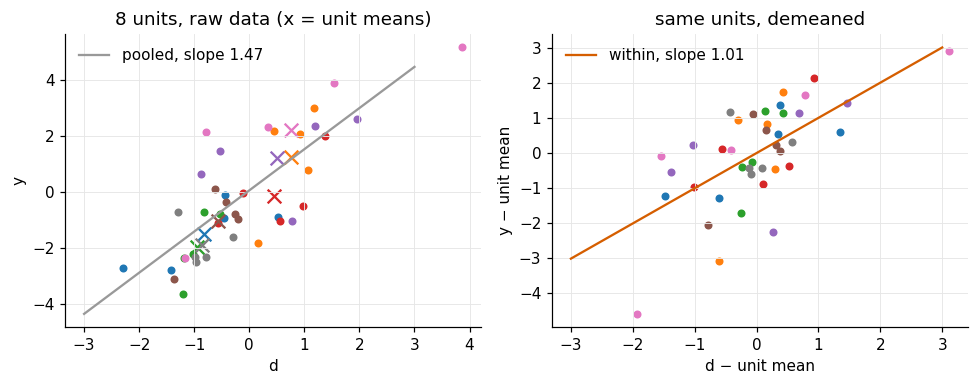

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
sub = df[df.i < 8]
for k, (uid, g) in enumerate(sub.groupby("i")):
    ax[0].scatter(g.d, g.y, s=18, color=plt.cm.tab10(k)); ax[0].scatter(g.d_bar.iloc[0], g.y_bar.iloc[0], marker="x", s=80, color=plt.cm.tab10(k))
    ax[1].scatter(g.d_w, g.y_w, s=18, color=plt.cm.tab10(k))
xs = np.linspace(-3, 3, 2)
ax[0].plot(xs, pooled.params["Intercept"] + pooled.params["d"] * xs, color=GREY, lw=1.5, label=f"pooled, slope {pooled.params['d']:.2f}")
ax[0].set_title("8 units, raw data (x = unit means)"); ax[0].set_xlabel("d"); ax[0].set_ylabel("y"); ax[0].legend(frameon=False)
ax[1].plot(xs, within.params["d_w"] * xs, color=VERMILLION, lw=1.5, label=f"within, slope {within.params['d_w']:.2f}")
ax[1].set_title("same units, demeaned"); ax[1].set_xlabel("d − unit mean"); ax[1].set_ylabel("y − unit mean"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 2. Three ways to the within estimator

1. Regress $y$ on $d$ and $N$ unit dummies (least-squares dummy variables).
2. Demean $y$ and $d$ within units and run OLS on the deviations.
3. A canned FE routine (`linearmodels.PanelOLS`, R `fixest`, Stata `xtreg, fe`).

Routes 1 and 2 give the *same* coefficient (Frisch–Waugh–Lovell: the dummies
are partialled out by demeaning). The standard errors differ unless the
demeaned regression is told that it has used up $N$ degrees of freedom:
$\hat\sigma^2$ must divide by $NT - N - K$, not $NT - K$.

In [4]:
lsdv = smf.ols("y ~ d + C(i)", df).fit()
N, T = df.i.nunique(), df.t.nunique()
dof_fix = np.sqrt((N * T - 1) / (N * T - N - 1))        # (NT − K) / (NT − N − K) with K = 1

out = pd.DataFrame({
    "coefficient": [lsdv.params["d"], within.params["d_w"], within.params["d_w"]],
    "SE":          [lsdv.bse["d"],   within.bse["d_w"],   within.bse["d_w"] * dof_fix],
}, index=["dummies (LSDV)", "demeaned, naive SE", "demeaned, DoF-corrected SE"])
out

,coefficient,SE
dummies (LSDV),1.0062,0.0355
"demeaned, naive SE",1.0062,0.0318
"demeaned, DoF-corrected SE",1.0062,0.0356


Two-way fixed effects add period dummies: the identifying variation is then
what is left after removing unit means *and* period means. Below the DGP gets
a common shock $\gamma_t$ that is correlated with $d$ (a trend in both); one-way
FE is biased again, two-way FE is not.

In [5]:
df2 = make_panel()
gamma_t = np.array([0, 0.5, 1.0, 1.5, 2.0])                     # common time shock, trending
df2["d"] = df2["d"] + 0.5 * gamma_t[df2.t]                      # treatment trends too
df2["y"] = df2["y"] + 0.5 * gamma_t[df2.t] + gamma_t[df2.t]     # y carries the shock and the d-part of it
oneway = smf.ols("y ~ d + C(i)", df2).fit()
twoway = smf.ols("y ~ d + C(i) + C(t)", df2).fit()
coef_table(oneway, twoway, names=["unit FE only", "unit + period FE"])

,unit FE only,unit + period FE
d,1.257 (0.041),0.957 (0.036)


## 3. Standard errors with a unit effect (Petersen 2009)

Now the question is not bias but *precision*: how far off are the usual
standard errors when both the regressor and the error contain a unit
component? Petersen's DGP:

$$x_{it} = \mu_i + \upsilon_{it}, \qquad \varepsilon_{it} = \gamma_i + \eta_{it},
\qquad \rho_x = \frac{\sigma_\mu^2}{\sigma_x^2},\; \rho_\varepsilon = \frac{\sigma_\gamma^2}{\sigma_\varepsilon^2},$$

with $\beta = 1$, $N = 500$ firms, $T = 10$ years. The true variance of $\hat\beta$
is $\frac{1}{NT}\frac{\sigma_\varepsilon^2}{\sigma_x^2}\,[1 + (T-1)\rho_x\rho_\varepsilon]$: the
OLS formula is right only if $\rho_x\rho_\varepsilon = 0$. We check three SE estimators
against the Monte Carlo SD of $\hat\beta$: OLS, heteroskedasticity-robust (HC1),
and clustered by firm — each without and with firm fixed effects.

In [6]:
def petersen_panel(N, T, rho_x, rho_e, phi=0.0, rng=rng):
    i = np.repeat(np.arange(N), T)
    def ar1(phi):                                             # unit-variance AR(1) within unit (iid if phi = 0)
        e = rng.normal(0, 1, (N, T))
        if phi == 0: return e.ravel()
        z = np.empty((N, T)); z[:, 0] = e[:, 0]
        for t in range(1, T): z[:, t] = phi * z[:, t - 1] + np.sqrt(1 - phi**2) * e[:, t]
        return z.ravel()
    mu = rng.normal(0, np.sqrt(rho_x), N)[i];  up  = np.sqrt(1 - rho_x) * ar1(phi)
    ga = rng.normal(0, np.sqrt(rho_e), N)[i];  eta = np.sqrt(1 - rho_e) * ar1(phi)
    x = mu + up; eps = ga + eta
    return pd.DataFrame({"i": i, "x": x, "y": 1.0 * x + eps})

def se_study(rho_x, rho_e, phi=0.0, N=500, T=10, reps=200, fe=False):
    b, se_ols, se_hc, se_cl = [], [], [], []
    for _ in range(reps):
        p = petersen_panel(N, T, rho_x, rho_e, phi)
        if fe:
            p["x"] = p["x"] - p.groupby("i")["x"].transform("mean"); p["y"] = p["y"] - p.groupby("i")["y"].transform("mean")
        X = sm.add_constant(p[["x"]])
        adj = np.sqrt((N * T - 2) / (N * T - N - 2)) if fe else 1.0     # DoF correction for the N absorbed means
        f = sm.OLS(p["y"], X).fit()
        b.append(f.params["x"]); se_ols.append(f.bse["x"] * adj)
        se_hc.append(sm.OLS(p["y"], X).fit(cov_type="HC1").bse["x"] * adj)
        se_cl.append(sm.OLS(p["y"], X).fit(cov_type="cluster", cov_kwds={"groups": p["i"]}).bse["x"] * adj)
    return pd.Series({"rho_x": rho_x, "rho_eps": rho_e, "phi": phi, "FE": fe, "MC SD of beta": np.std(b),
                      "OLS SE": np.mean(se_ols), "robust SE": np.mean(se_hc), "clustered SE": np.mean(se_cl)})

grid = [(0, 0), (0.5, 0), (0, 0.5), (0.5, 0.5), (0.75, 0.75)]
res = pd.DataFrame([se_study(rx, re) for rx, re in grid]).set_index(["rho_x", "rho_eps", "phi", "FE"])
res

,,,,MC SD of beta,OLS SE,robust SE,clustered SE
rho_x,rho_eps,phi,FE,,,,
0.0000,0.0000,0.0000,False,0.0142,0.0141,0.0142,0.0142
0.5000,0.0000,0.0000,False,0.0135,0.0142,0.0142,0.0141
0.0000,0.5000,0.0000,False,0.0146,0.0142,0.0141,0.0141
0.5000,0.5000,0.0000,False,0.0246,0.0141,0.0141,0.0253
0.7500,0.7500,0.0000,False,0.0358,0.0142,0.0142,0.0349


Reading the rows: with either $\rho$ at zero the three SEs agree with the Monte
Carlo SD. Once both are positive, OLS and robust SEs are too small — at
$\rho_x = \rho_\varepsilon = 0.5$ the true SD is almost double the reported SE,
and $t$-statistics are inflated accordingly. The clustered SE tracks the truth
throughout. Robust SEs fix heteroskedasticity, not within-unit correlation —
a different problem.

Now the same with firm fixed effects. If the unit component of the error is
a *constant* $\gamma_i$, demeaning removes it and the OLS SE is right again.
If instead the within-firm correlation *decays* (AR(1) idiosyncratic parts
in both $x$ and $\varepsilon$, $\phi = 0.9$ — Petersen's scenario II), demeaning
removes the mean but not the serial correlation — the OLS SE is wrong again,
and only the clustered SE survives. (Both components must be correlated for
the OLS SE to fail; that is why the earlier rows with one $\rho$ at zero were
fine.)

In [7]:
res_fe = pd.DataFrame([se_study(0.5, 0.5, fe=True), se_study(0.5, 0.5, phi=0.9, fe=False), se_study(0.5, 0.5, phi=0.9, fe=True)]
                      ).set_index(["rho_x", "rho_eps", "phi", "FE"])
res_fe

MC SD of beta  OLS SE  robust SE  clustered SE
rho_x  rho_eps phi    FE                                                   
0.5000 0.5000  0.0000 True          0.0155  0.0149     0.0149        0.0157
               0.9000 False         0.0383  0.0141     0.0141        0.0386
                      True          0.0268  0.0149     0.0157        0.0271

## 4. When clustering hurts (Abadie, Athey, Imbens and Wooldridge 2023)

Clustered SEs are not free: they are the right answer only when there is
something to cluster over. Two designs with $G = 50$ clusters of 40 units,
a binary treatment and treatment effects that differ by cluster
($\tau_g \sim N(1, 0.5^2)$):

- **Design A**: treatment assigned at the *individual* level, 50 % within every
  cluster. The sample *is* the population of clusters.
- **Design B**: treatment assigned at the *cluster* level (whole clusters
  treated or not).

For each we compare the Monte Carlo SD of $\hat\tau$ with the robust and the
clustered SE.

In [8]:
def abadie_design(cluster_level, G=50, n=40, reps=300, rng=rng):
    g = np.repeat(np.arange(G), n); tau_g = rng.normal(1.0, 0.5, G)         # fixed across reps: finite population of clusters
    b, se_hc, se_cl = [], [], []
    for _ in range(reps):
        if cluster_level:
            dg = rng.binomial(1, 0.5, G); d = dg[g]
        else:
            d = np.tile(np.r_[np.ones(n // 2), np.zeros(n // 2)], G); d = np.concatenate([rng.permutation(d[g == k]) for k in range(G)])
        y = tau_g[g] * d + rng.normal(0, 1, G * n) + rng.normal(0, 0.3, G)[g]
        X = sm.add_constant(d)
        b.append(sm.OLS(y, X).fit().params[1])
        se_hc.append(sm.OLS(y, X).fit(cov_type="HC1").bse[1])
        se_cl.append(sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": g}).bse[1])
    return pd.Series({"MC SD of tau": np.std(b), "robust SE": np.mean(se_hc), "clustered SE": np.mean(se_cl)})

pd.DataFrame({"A: individual-level assignment": abadie_design(False), "B: cluster-level assignment": abadie_design(True)}).T

,MC SD of tau,robust SE,clustered SE
A: individual-level assignment,0.0456,0.0495,0.0864
B: cluster-level assignment,0.1202,0.0499,0.1411


In design A the clustered SE is far too large — it charges for cluster-level
heterogeneity in $\tau_g$ that never varies across samples, because every
cluster is always half treated. The robust SE is right. In design B the
assignment itself is clustered; the robust SE is far too small and clustering
is essential. The rule on the slide: cluster if effects are heterogeneous
*and* (sampling or assignment is clustered). The level of the fixed effect is
not the criterion.

## 5. Fixed effects in a nonlinear model: the incidental-parameters problem

A logit with unit dummies and short $T$ is inconsistent for fixed $T$: each
$\alpha_i$ is estimated from $T$ observations, and the noise in the $N$
nuisance parameters contaminates $\hat\beta$. With $T = 2$ the slope is
roughly doubled (Andersen 1970; Neyman–Scott 1948). The conditional logit
conditions on $\sum_t y_{it}$, which removes $\alpha_i$ exactly. We simulate
$N = 500$, $T = 2$, $\beta = 1$:

In [9]:
from statsmodels.discrete.conditional_models import ConditionalLogit

def logit_panel(N=500, T=2, beta=1.0, rng=rng):
    alpha = rng.normal(0, 1, N); i = np.repeat(np.arange(N), T)
    x = 0.5 * alpha[i] + rng.normal(0, 1, N * T)
    p = 1 / (1 + np.exp(-(alpha[i] + beta * x)))
    return pd.DataFrame({"i": i, "x": x, "y": rng.binomial(1, p)})

b_dummy, b_cond, b_lpm = [], [], []
for _ in range(100):
    p = logit_panel()
    try:
        b_dummy.append(smf.logit("y ~ x + C(i)", p).fit(disp=0, maxiter=200).params["x"])
    except Exception:
        pass
    keep = p.groupby("i")["y"].transform(lambda s: 0 < s.sum() < len(s))      # only switchers inform the conditional logit
    q = p[keep]
    b_cond.append(ConditionalLogit(q["y"], q[["x"]], groups=q["i"]).fit(disp=0).params.iloc[0])
    p["x_w"] = p["x"] - p.groupby("i")["x"].transform("mean"); p["y_w"] = p["y"] - p.groupby("i")["y"].transform("mean")
    b_lpm.append(smf.ols("y_w ~ x_w", p).fit().params["x_w"])

pd.DataFrame({"mean estimate": [np.mean(b_dummy), np.mean(b_cond), np.mean(b_lpm)],
              "truth": [1.0, 1.0, "n/a (marginal effect)"]},
             index=["logit with unit dummies", "conditional logit", "LPM with FE (within)"])

,mean estimate,truth
logit with unit dummies,2.0385,1.0000
conditional logit,1.0193,1.0000
LPM with FE (within),0.1605,n/a (marginal effect)


The dummy-variable logit overshoots by a wide margin; the conditional logit is
centred on 1 (it uses only units whose outcome switches — the others carry no
within information). The linear probability model with fixed effects answers a
different question (an average marginal effect, not a logit index coefficient),
which is why it cannot be compared with 1 — but it has no incidental-parameters
problem, which is the trade the slide describes.

## Summary

- Fixed effects = identification from within-unit variation; between variation
  is thrown away, and with it every time-invariant confounder.
- Dummies and demeaning are the same estimator; the demeaned regression needs
  the degrees-of-freedom correction. Two-way FE removes unit and period means.
- A unit component in both $x$ and $\varepsilon$ makes OLS and robust SEs too
  small by $\sqrt{1 + (T-1)\rho_x\rho_\varepsilon}$; FE repairs this only if the
  component is constant — decaying components still need clustering.
- Clustering is a design question, not a reflex: heterogeneous effects *and*
  clustered sampling or assignment. Otherwise it only widens intervals.
- Nonlinear models with many dummies and short $T$ are inconsistent; use
  conditional logit, Poisson FE, or the linear probability model.